<a href="https://colab.research.google.com/github/abdulrafaykhan11/House-Prediction-ml/blob/main/House_Price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('house_prices.csv')

In [ ]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              14365 non-null  int64  
 1   Title              14365 non-null  object 
 2   Description        14261 non-null  object 
 3   Amount(in rupees)  14365 non-null  object 
 4   Price (in rupees)  13567 non-null  float64
 5   location           14365 non-null  object 
 6   Carpet Area        7778 non-null   object 
 7   Status             14346 non-null  object 
 8   Floor              13890 non-null  object 
 9   Transaction        14355 non-null  object 
 10  Furnishing         14284 non-null  object 
 11  facing             7776 non-null   object 
 12  overlooking        7999 non-null   object 
 13  Society            8364 non-null   object 
 14  Bathroom           14335 non-null  object 
 15  Balcony            9515 non-null   object 
 16  Car Parking        572

In [ ]:
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,14365.000000,13567.000000,0.0,0.0
mean,7182.000000,7004.182281,NaN,NaN
std,4146.962644,5990.344663,NaN,NaN
min,0.000000,1583.000000,NaN,NaN
25%,3591.000000,4275.000000,NaN,NaN
50%,7182.000000,5271.000000,NaN,NaN
75%,10773.000000,6878.000000,NaN,NaN
max,14364.000000,84619.000000,NaN,NaN


In [ ]:
df.drop(['Dimensions','Plot Area'],inplace=True,axis=1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              14365 non-null  int64  
 1   Title              14365 non-null  object 
 2   Description        14261 non-null  object 
 3   Amount(in rupees)  14365 non-null  object 
 4   Price (in rupees)  13567 non-null  float64
 5   location           14365 non-null  object 
 6   Carpet Area        7778 non-null   object 
 7   Status             14346 non-null  object 
 8   Floor              13890 non-null  object 
 9   Transaction        14355 non-null  object 
 10  Furnishing         14284 non-null  object 
 11  facing             7776 non-null   object 
 12  overlooking        7999 non-null   object 
 13  Society            8364 non-null   object 
 14  Bathroom           14335 non-null  object 
 15  Balcony            9515 non-null   object 
 16  Car Parking        572

In [ ]:
df['Amount(in rupees)'].unique()

array(['42 Lac ', '98 Lac ', '1.40 Cr ', '25 Lac ', '1.60 Cr ', '45 Lac ',
       '16.5 Lac ', '60 Lac ', '1.36 Cr ', '1.35 Cr ', '4.25 Cr ',
       '75 Lac ', '90 Lac ', '37 Lac ', '35 Lac ', '54 Lac ', '1.65 Cr ',
       '85 Lac ', '1.28 Cr ', 'Call for Price', '24 Lac ', '61 Lac ',
       '1.75 Cr ', '47 Lac ', '3.20 Cr ', '1.98 Cr ', '83 Lac ',
       '1.42 Cr ', '26 Lac ', '70 Lac ', '1.18 Cr ', '20 Lac ',
       '1.10 Cr ', '1.05 Cr ', '78 Lac ', '1.55 Cr ', '12 Lac ',
       '32 Lac ', '23 Lac ', '1 Cr ', '50 Lac ', '30 Lac ', '1.20 Cr ',
       '51 Lac ', '1.90 Cr ', '40 Lac ', '43 Lac ', '2.60 Cr ',
       '2.65 Cr ', '53 Lac ', '2.40 Cr ', '3.10 Cr ', '2 Cr ', '22 Lac ',
       '79 Lac ', '48 Lac ', '75.2 Lac ', '1.32 Cr ', '28 Lac ',
       '77 Lac ', '1.19 Cr ', '68 Lac ', '4 Cr ', '68.6 Lac ', '99 Lac ',
       '44.3 Lac ', '55 Lac ', '33 Lac ', '95 Lac ', '2.10 Cr ',
       '15 Lac ', '97 Lac ', '27 Lac ', '41 Lac ', '42.9 Lac ',
       '2.36 Cr ', '29 Lac ', '27.5 Lac ',

In [ ]:
df['Amount(in rupees)'] = (
    df['Amount(in rupees)']
    .astype(str)
    .str.lower()
    .str.replace(' ', '', regex=False)
    .str.replace('cr', 'e7', regex=False)
    .str.replace('lac', 'e5', regex=False)
)

# Numeric me convert karke int bana lo
df['Amount(in rupees)'] = pd.to_numeric(df['Amount(in rupees)'], errors='coerce').astype('Int64')

In [ ]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,110 sqyrd,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,NaN,Freehold,NaN
14361,14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,NaN,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,NaN,1485 sqft
14362,14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,180 sqyrd,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,1 Covered,Freehold,NaN
14363,14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,175 sqyrd,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,1 Covered,Leasehold,NaN


In [16]:
df['Carpet Area'].unique()

array(['500 sqft', '473 sqft', '779 sqft', ..., '4734 sqft', '2623 sqft',
       '1707 sqft'], dtype=object)

In [17]:
df['Carpet Area'] = df['Carpet Area'].astype(str).str.lower().str.replace('sqft', '', regex=False)

In [18]:
df['Carpet Area'] = pd.to_numeric(df['Carpet Area'] , errors='coerce').astype('Int64')

In [19]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,NaN,Freehold,NaN
14361,14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,NaN,1485 sqft
14362,14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,1 Covered,Freehold,NaN
14363,14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,1 Covered,Leasehold,NaN


In [22]:
df['Bathroom'].unique()

array(['1', '2', '3', '4', '6', nan, '5', '10', '9', '8', '> 10', '7'],
      dtype=object)

In [23]:
df['Bathroom'] = df['Bathroom'].astype(str).str.lower().str.replace('>10', '10', regex=False)

In [25]:
df['Bathroom'] = pd.to_numeric(df['Bathroom'],errors='coerce').astype('Int64')

In [26]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,NaN,Freehold,NaN
14361,14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,NaN,1485 sqft
14362,14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,1 Covered,Freehold,NaN
14363,14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,1 Covered,Leasehold,NaN


In [27]:
df['Balcony'].unique()

array(['2', nan, '1', '3', '4', '> 10', '6', '5', '7', '10'], dtype=object)

In [33]:
df['Balcony'] = df['Balcony'].astype(str).str.lower().str.replace('>10', '10', regex=False)
df['Balcony'] = pd.to_numeric(df['Balcony'] , errors='coerce').astype('Int64')

In [35]:
df['Balcony'].unique()

<IntegerArray>
[2, <NA>, 1, 3, 4, 6, 5, 7, 10]
Length: 9, dtype: Int64

In [36]:
df['Car Parking'].unique()

array([nan, '1 Open', '1 Covered', '2 Covered', '66 Covered',
       '701 Covered', '3 Covered', '1 Covered,', '35 Open', '4 Open',
       '323 Covered', '4 Covered,', '11 Covered', '103 Open',
       '203 Covered', '2 Open', '180 Covered', '14 Open', '50 Open',
       '10 Covered', '15 Open', '5 Open', '7 Covered', '4 Covered',
       '509 Covered,', '6 Covered', '101 Covered', '5 Covered,',
       '6 Covered,', '3 Covered,', '123 Covered', '505 Covered',
       '402 Covered', '8 Covered', '5 Covered', '2 Covered,',
       '103 Covered', '12 Covered,', '202 Open', '202 Covered',
       '20 Covered,', '503 Open', '401 Covered', '3 Open', '501 Covered',
       '10 Covered,'], dtype=object)

In [37]:
df['Car Parking Count'] = (
    df['Car Parking']
    .astype(str)
    .str.extract(r'(\d+)', expand=False)
)
df['Car Parking Count'] = pd.to_numeric(df['Car Parking Count'], errors='coerce').astype('Int64')

df['Car Parking Type'] = (
    df['Car Parking']
    .astype(str)
    .str.extract(r'(Open|Covered)', expand=False)
)

In [38]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Car Parking Count,Car Parking Type
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,<NA>,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,<NA>,1 Open,Freehold,NaN,1,Open
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,<NA>,1 Covered,Freehold,NaN,1,Covered
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,<NA>,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,<NA>,1 Covered,Co-operative Society,NaN,1,Covered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,...,East,Main Road,Ashraya 9,3,2,NaN,Freehold,NaN,<NA>,NaN
14361,14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,...,NaN,NaN,Palladian Greens,3,1,NaN,NaN,1485 sqft,<NA>,NaN
14362,14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,...,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,1 Covered,Freehold,NaN,1,Covered
14363,14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,...,West,"Garden/Park, Pool, Main Road",NaN,3,1,1 Covered,Leasehold,NaN,1,Covered


In [40]:
df.drop('Car Parking',inplace=True,axis=1)

In [41]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Ownership,Super Area,Car Parking Count,Car Parking Type
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,<NA>,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,<NA>,Freehold,NaN,1,Open
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,<NA>,Freehold,NaN,1,Covered
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,<NA>,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,<NA>,Co-operative Society,NaN,1,Covered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,Freehold,NaN,<NA>,NaN
14361,14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,1485 sqft,<NA>,NaN
14362,14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,Freehold,NaN,1,Covered
14363,14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,Leasehold,NaN,1,Covered


In [42]:
df.drop('Index',axis=1,inplace=True)

In [43]:
df

,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Ownership,Super Area,Car Parking Count,Car Parking Type
0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,<NA>,NaN
1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,<NA>,Freehold,NaN,1,Open
2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,<NA>,Freehold,NaN,1,Covered
3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,<NA>,NaN
4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,<NA>,Co-operative Society,NaN,1,Covered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,Freehold,NaN,<NA>,NaN
14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,1485 sqft,<NA>,NaN
14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,Freehold,NaN,1,Covered
14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,Leasehold,NaN,1,Covered


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14261 non-null  object 
 2   Amount(in rupees)  14116 non-null  Int64  
 3   Price (in rupees)  13567 non-null  float64
 4   location           14365 non-null  object 
 5   Carpet Area        5471 non-null   Int64  
 6   Status             14346 non-null  object 
 7   Floor              13890 non-null  object 
 8   Transaction        14355 non-null  object 
 9   Furnishing         14284 non-null  object 
 10  facing             7776 non-null   object 
 11  overlooking        7999 non-null   object 
 12  Society            8364 non-null   object 
 13  Bathroom           14333 non-null  Int64  
 14  Balcony            9511 non-null   Int64  
 15  Ownership          8800 non-null   object 
 16  Super Area         658

In [48]:

print(df[['Amount(in rupees)', 'Price (in rupees)','Carpet Area']].head(10))

   Amount(in rupees)  Price (in rupees)  Carpet Area
0            4200000             6000.0          500
1            9800000            13799.0          473
2           14000000            17500.0          779
3            2500000                NaN          530
4           16000000            18824.0          635
5            4500000             6618.0         <NA>
6            1650000             2538.0          550
7            6000000            10435.0         <NA>
8            6000000            10000.0         <NA>
9           16000000            11150.0          900


In [49]:
df = df.rename(columns={
    'Amount(in rupees)': 'total amount',
    'Price (in rupees)': 'price'
})

In [50]:
df

,Title,Description,total amount,price,location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Ownership,Super Area,Car Parking Count,Car Parking Type
0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,500,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,<NA>,NaN
1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,473,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,<NA>,Freehold,NaN,1,Open
2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,779,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,<NA>,Freehold,NaN,1,Covered
3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,530,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,<NA>,NaN
4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,635,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,<NA>,Co-operative Society,NaN,1,Covered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,<NA>,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,Freehold,NaN,<NA>,NaN
14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,<NA>,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,1485 sqft,<NA>,NaN
14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,<NA>,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,Freehold,NaN,1,Covered
14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,<NA>,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,Leasehold,NaN,1,Covered


In [51]:
print(df[['Super Area','Carpet Area']].head(10))

  Super Area  Carpet Area
0        NaN          500
1        NaN          473
2        NaN          779
3        NaN          530
4        NaN          635
5   680 sqft         <NA>
6        NaN          550
7   575 sqft         <NA>
8   600 sqft         <NA>
9        NaN          900


In [52]:
df['Super Area'] = (
    df['Super Area']
    .astype(str)
    .str.lower()
    .str.replace(r'sq\.?\s*ft', '', regex=True)
    .str.replace(' ', '', regex=False)
)

In [54]:
df['Super Area']

,Super Area
0,nan
1,nan
2,nan
3,nan
4,nan
...,...
14360,nan
14361,1485
14362,nan
14363,nan


In [60]:
df['Super Area'] = pd.to_numeric(
    df['Super Area'].astype(str).str.lower().str.replace(r'sq\.?\s*ft', '', regex=True).str.replace(' ', '', regex=False),
    errors='coerce'
)

df['Carpet Area'] = pd.to_numeric(df['Carpet Area'], errors='coerce')

df['Area'] = df['Super Area'].fillna(df['Carpet Area'])


df = df.drop(columns=['Super Area', 'Carpet Area'])

KeyError: 'Super Area'

In [58]:

df['Area'] = df['Super Area'].fillna(df['Carpet Area'])
df = df.drop(columns=['Super Area', 'Carpet Area'])

In [56]:
df

,Title,Description,total amount,price,location,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Ownership,Car Parking Count,Car Parking Type,Area
0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.0,thane,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,<NA>,NaN,nan
1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.0,thane,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,<NA>,Freehold,1,Open,nan
2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.0,thane,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,<NA>,Freehold,1,Covered,nan
3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,NaN,thane,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,<NA>,NaN,nan
4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.0,thane,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,<NA>,Co-operative Society,1,Covered,nan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.0,ahmedabad,Ready to Move,1 out of 7,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,Freehold,<NA>,NaN,nan
14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.0,ahmedabad,Ready to Move,3 out of 16,Resale,Unfurnished,NaN,NaN,Palladian Greens,3,1,NaN,<NA>,NaN,1485
14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.0,ahmedabad,Ready to Move,4 out of 7,Resale,Unfurnished,NaN,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,Freehold,1,Covered,nan
14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.0,ahmedabad,Ready to Move,4 out of 5,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",NaN,3,1,Leasehold,1,Covered,nan


In [57]:
print(df['Area'].head(10))

0    nan
1    nan
2    nan
3    nan
4    nan
5    680
6    nan
7    575
8    600
9    nan
Name: Area, dtype: object


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14261 non-null  object 
 2   total amount       14116 non-null  Int64  
 3   price              13567 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14346 non-null  object 
 6   Floor              13890 non-null  object 
 7   Transaction        14355 non-null  object 
 8   Furnishing         14284 non-null  object 
 9   facing             7776 non-null   object 
 10  overlooking        7999 non-null   object 
 11  Society            8364 non-null   object 
 12  Bathroom           14333 non-null  Int64  
 13  Balcony            9511 non-null   Int64  
 14  Ownership          8800 non-null   object 
 15  Car Parking Count  5726 non-null   Int64  
 16  Car Parking Type   572

In [65]:
df['Area'] = (
    df['Area']
    .astype(str)
    .str.lower()
    .str.replace(r'sq\.?\s*ft', '', regex=True)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['Area'] = pd.to_numeric(df['Area'], errors='coerce').astype('Int64')

In [66]:
df['Area']

,Area
0,<NA>
1,<NA>
2,<NA>
3,<NA>
4,<NA>
...,...
14360,<NA>
14361,1485
14362,<NA>
14363,<NA>


In [70]:
df['Area'] = pd.to_numeric(df['Area'].astype(str).str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
mask = df['Area'].isna() & df['total amount'].notna() & df['price'].notna()
df.loc[mask, 'Area'] = df['total amount'] / df['price']

In [72]:
df['Area'] = df['Area'].fillna(df['Area'].mean())

In [75]:
df['Area'] = df['Area'].round(2)

In [76]:
df['Area']

,Area
0,700.00
1,710.20
2,800.00
3,1549.41
4,849.98
...,...
14360,1485.15
14361,1485.00
14362,1620.05
14363,2069.92


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14261 non-null  object 
 2   total amount       14116 non-null  Int64  
 3   price              13567 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14346 non-null  object 
 6   Floor              13890 non-null  object 
 7   Transaction        14355 non-null  object 
 8   Furnishing         14284 non-null  object 
 9   facing             7776 non-null   object 
 10  overlooking        7999 non-null   object 
 11  Society            8364 non-null   object 
 12  Bathroom           14333 non-null  Int64  
 13  Balcony            9511 non-null   Int64  
 14  Ownership          8800 non-null   object 
 15  Car Parking Count  5726 non-null   Int64  
 16  Car Parking Type   572

In [79]:
print(df.head(10))

                                               Title  \
0  1 BHK Ready to Occupy Flat for sale in Srushti...   
1  2 BHK Ready to Occupy Flat for sale in Dosti V...   
2  2 BHK Ready to Occupy Flat for sale in Sunrise...   
3        1 BHK Ready to Occupy Flat for sale Kasheli   
4  2 BHK Ready to Occupy Flat for sale in TenX Ha...   
5  1 BHK Ready to Occupy Flat for sale in Virat A...   
6         1 BHK Ready to Occupy Flat for sale Mumbra   
7          1 BHK Ready to Occupy Flat for sale Kalwa   
8          1 BHK Ready to Occupy Flat for sale Kalwa   
9  3 BHK Ready to Occupy Flat for sale in Pride P...   

                                         Description  total amount    price  \
0  Bhiwandi, Thane has an attractive 1 BHK Flat f...       4200000   6000.0   
1  One can find this stunning 2 BHK flat for sale...       9800000  13799.0   
2  Up for immediate sale is a 2 BHK apartment in ...      14000000  17500.0   
3  This beautiful 1 BHK Flat is available for sal...       2500000 

In [84]:
df['Society'] = df['Society'].fillna('Unknown')

In [86]:
df['Society']

,Society
0,Srushti Siddhi Mangal Murti Complex
1,Dosti Vihar
2,Sunrise by Kalpataru
3,Unknown
4,TenX Habitat Raymond Realty
...,...
14360,Ashraya 9
14361,Palladian Greens
14362,Raj Harsh Appartment
14363,Unknown


In [89]:
df['overlooking']

,overlooking
0,Not Specified
1,Garden/Park
2,Garden/Park
3,Not Specified
4,"Garden/Park, Main Road"
...,...
14360,Main Road
14361,Not Specified
14362,"Garden/Park, Main Road"
14363,"Garden/Park, Pool, Main Road"


In [88]:
df['overlooking'] = df['overlooking'].fillna('Not Specified')

In [92]:
df['facing']

,facing
0,NaN
1,East
2,East
3,NaN
4,West
...,...
14360,East
14361,NaN
14362,NaN
14363,West


In [93]:
df['facing'] = df['facing'].fillna('Not Specified')

In [95]:
print(df['Floor'])

0        10 out of 11
1         3 out of 22
2        10 out of 29
3          1 out of 3
4        20 out of 42
             ...     
14360      1 out of 7
14361     3 out of 16
14362      4 out of 7
14363      4 out of 5
14364     16 out of 1
Name: Floor, Length: 14365, dtype: object


In [96]:

floor_split = df['Floor'].astype(str).str.split(' out of ', expand=True)


df['Floor_Num'] = pd.to_numeric(floor_split[0], errors='coerce')
df['Total_Floors'] = pd.to_numeric(floor_split[1], errors='coerce')

df = df.drop(columns=['Floor'], errors='ignore')

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14261 non-null  object 
 2   total amount       14116 non-null  Int64  
 3   price              13567 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14346 non-null  object 
 6   Transaction        14355 non-null  object 
 7   Furnishing         14284 non-null  object 
 8   facing             14365 non-null  object 
 9   overlooking        14365 non-null  object 
 10  Society            14365 non-null  object 
 11  Bathroom           14333 non-null  Int64  
 12  Balcony            9511 non-null   Int64  
 13  Ownership          8800 non-null   object 
 14  Car Parking Count  5726 non-null   Int64  
 15  Car Parking Type   5726 non-null   object 
 16  Area               143

In [101]:
print(df[['Floor_Num','Total_Floors']].head(10))

   Floor_Num  Total_Floors
0       10.0          11.0
1        3.0          22.0
2       10.0          29.0
3        1.0           3.0
4       20.0          42.0
5        2.0           7.0
6        4.0           5.0
7        NaN           7.0
8        NaN           2.0
9        3.0          27.0


In [102]:
print(df['location'].value_counts().head(10))

location
ahmedabad      11744
thane            972
mumbai           932
navi-mumbai      360
nagpur           357
Name: count, dtype: int64


In [103]:
df['Description'] = df['Description'].fillna('No Description')

df['Status'] = df['Status'].fillna('Unknown')
df['Transaction'] = df['Transaction'].fillna('Unknown')
df['Furnishing'] = df['Furnishing'].fillna('Not Specified')
df['Ownership'] = df['Ownership'].fillna('Unknown')

df['Bathroom'] = df['Bathroom'].fillna(df['Bathroom'].median())
df['Balcony'] = df['Balcony'].fillna(0)

if 'Car Parking Count' in df.columns:
    df['Car Parking Count'] = df['Car Parking Count'].fillna(0)
    df['Car Parking Type'] = df['Car Parking Type'].fillna('No Parking')

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14365 non-null  object 
 2   total amount       14116 non-null  Int64  
 3   price              13567 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14365 non-null  object 
 6   Transaction        14365 non-null  object 
 7   Furnishing         14365 non-null  object 
 8   facing             14365 non-null  object 
 9   overlooking        14365 non-null  object 
 10  Society            14365 non-null  object 
 11  Bathroom           14365 non-null  Int64  
 12  Balcony            14365 non-null  Int64  
 13  Ownership          14365 non-null  object 
 14  Car Parking Count  14365 non-null  Int64  
 15  Car Parking Type   14365 non-null  object 
 16  Area               143

In [105]:
mask_price = df['price'].isna() & df['total amount'].notna() & df['Area'].notna() & (df['Area'] > 0)
df.loc[mask_price, 'price'] = df['total amount'] / df['Area']

mask_total = df['total amount'].isna() & df['price'].notna() & df['Area'].notna()
df.loc[mask_total, 'total amount'] = df['price'] * df['Area']

df['Floor_Num'] = df['Floor_Num'].fillna(df['Floor_Num'].median())
df['Total_Floors'] = df['Total_Floors'].fillna(df['Total_Floors'].median())

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14365 non-null  object 
 2   total amount       14116 non-null  Int64  
 3   price              14116 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14365 non-null  object 
 6   Transaction        14365 non-null  object 
 7   Furnishing         14365 non-null  object 
 8   facing             14365 non-null  object 
 9   overlooking        14365 non-null  object 
 10  Society            14365 non-null  object 
 11  Bathroom           14365 non-null  Int64  
 12  Balcony            14365 non-null  Int64  
 13  Ownership          14365 non-null  object 
 14  Car Parking Count  14365 non-null  Int64  
 15  Car Parking Type   14365 non-null  object 
 16  Area               143

In [110]:
df['total amount'] = df['total amount'].fillna(df['total amount'].median())
df['price'] = df['price'].fillna(df['price'].median())

In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              14365 non-null  object 
 1   Description        14365 non-null  object 
 2   total amount       14365 non-null  Int64  
 3   price              14365 non-null  float64
 4   location           14365 non-null  object 
 5   Status             14365 non-null  object 
 6   Transaction        14365 non-null  object 
 7   Furnishing         14365 non-null  object 
 8   facing             14365 non-null  object 
 9   overlooking        14365 non-null  object 
 10  Society            14365 non-null  object 
 11  Bathroom           14365 non-null  Int64  
 12  Balcony            14365 non-null  Int64  
 13  Ownership          14365 non-null  object 
 14  Car Parking Count  14365 non-null  Int64  
 15  Car Parking Type   14365 non-null  object 
 16  Area               143

In [108]:
df

,Title,Description,total amount,price,location,Status,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Ownership,Car Parking Count,Car Parking Type,Area,Floor_Num,Total_Floors
0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000,6000.000000,thane,Ready to Move,Resale,Unfurnished,Not Specified,Not Specified,Srushti Siddhi Mangal Murti Complex,1,2,Unknown,0,No Parking,700.00,10.0,11.0
1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000,13799.000000,thane,Ready to Move,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,0,Freehold,1,Open,710.20,3.0,22.0
2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000,17500.000000,thane,Ready to Move,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,0,Freehold,1,Covered,800.00,10.0,29.0
3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000,1613.517403,thane,Ready to Move,Resale,Unfurnished,Not Specified,Not Specified,Unknown,1,1,Unknown,0,No Parking,1549.41,1.0,3.0
4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000,18824.000000,thane,Ready to Move,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,0,Co-operative Society,1,Covered,849.98,20.0,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14360,3 BHK Ready to Occupy Flat for sale in Ashraya...,Have a look at this immaculate 3 BHK flat for ...,5100000,3434.000000,ahmedabad,Ready to Move,Resale,Unfurnished,East,Main Road,Ashraya 9,3,2,Freehold,0,No Parking,1485.15,1.0,7.0
14361,3 BHK Ready to Occupy Flat for sale in Palladi...,One can find this stunning 3 BHK flat for sale...,6500000,4377.000000,ahmedabad,Ready to Move,Resale,Unfurnished,Not Specified,Not Specified,Palladian Greens,3,1,Unknown,0,No Parking,1485.00,3.0,16.0
14362,3 BHK Ready to Occupy Flat for sale in Raj Har...,One can find this stunning 3 BHK flat for sale...,9500000,5864.000000,ahmedabad,Ready to Move,Resale,Unfurnished,Not Specified,"Garden/Park, Main Road",Raj Harsh Appartment,3,3,Freehold,1,Covered,1620.05,4.0,7.0
14363,3 BHK Ready to Occupy Flat for sale Jodhpur Ga...,This exquisite 3 BHK Flat is offered for sale ...,13500000,6522.000000,ahmedabad,Ready to Move,Resale,Semi-Furnished,West,"Garden/Park, Pool, Main Road",Unknown,3,1,Leasehold,1,Covered,2069.92,4.0,5.0


In [112]:
df.describe()

,total amount,price,Bathroom,Balcony,Car Parking Count,Area,Floor_Num,Total_Floors
count,14365.0,14365.000000,14365.0,14365.0,14365.0,14365.000000,14365.000000,14365.000000
mean,11592476.853463,7323.475472,2.552384,1.051514,0.941733,1549.407394,4.798608,9.667873
std,15168720.473997,6417.505938,0.925889,0.972823,12.719289,851.396620,4.609269,6.854783
min,200000.0,839.029050,1.0,0.0,0.0,27.000000,1.000000,1.000000
25%,5200000.0,4335.000000,2.0,0.0,0.0,1025.020000,2.000000,5.000000
50%,7000000.0,5278.500000,2.0,1.0,0.0,1485.000000,4.000000,7.000000
75%,12000000.0,6878.000000,3.0,2.0,1.0,1962.030000,6.000000,13.000000
max,420000000.0,90356.974590,10.0,10.0,701.0,15000.000000,75.000000,91.000000


<Axes: >

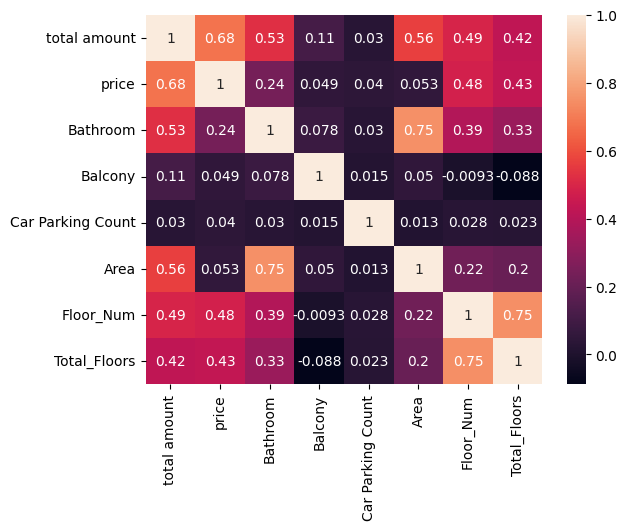

In [113]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [114]:
df = df.drop(columns=['Car Parking Count', 'Car Parking Type'], errors='ignore')

<Axes: xlabel='total amount', ylabel='Bathroom'>

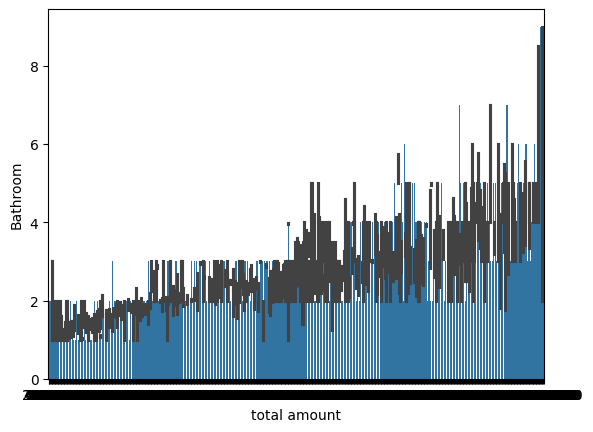

In [129]:
sns.barplot(x='total amount',y='Bathroom',data=df)

<Axes: xlabel='Bathroom', ylabel='Count'>

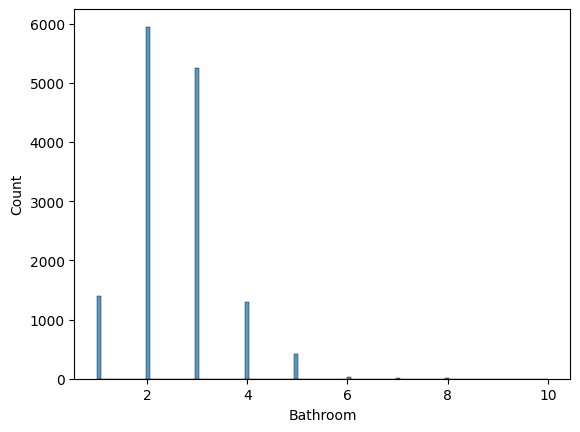

In [131]:
sns.histplot(df['Bathroom'])

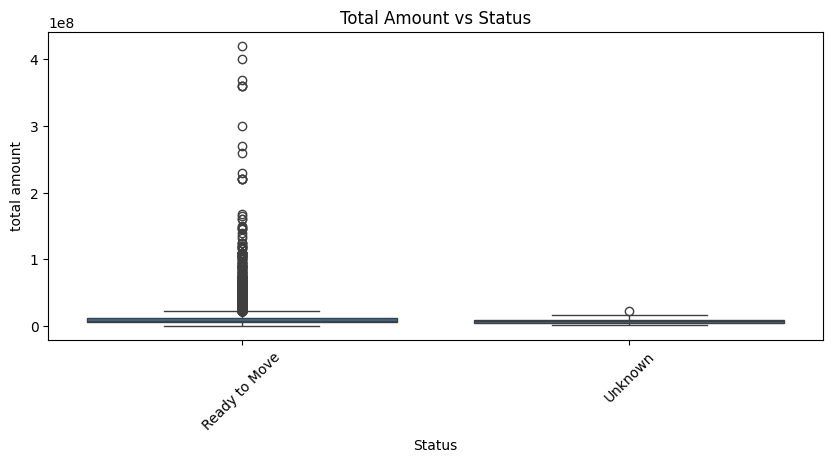

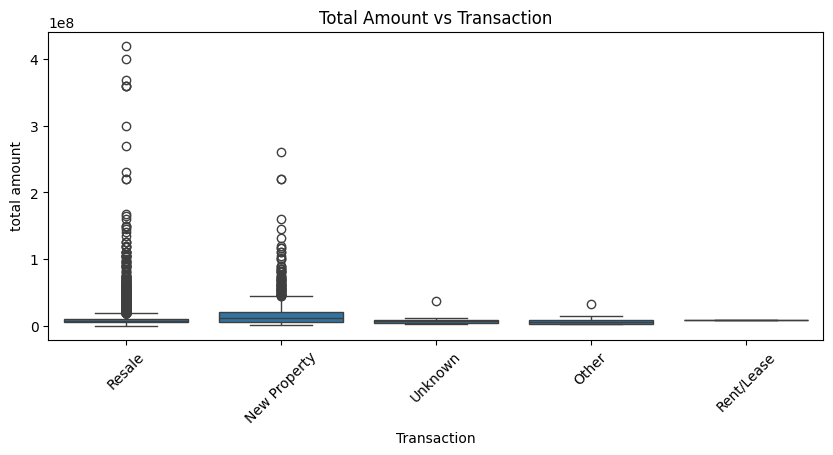

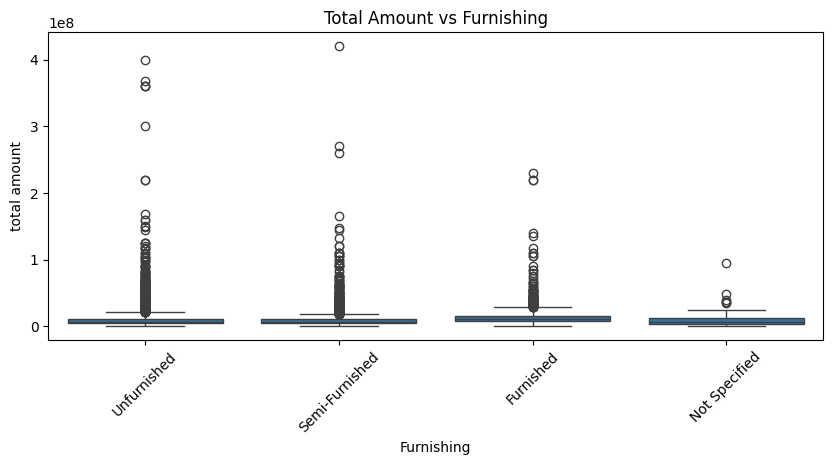

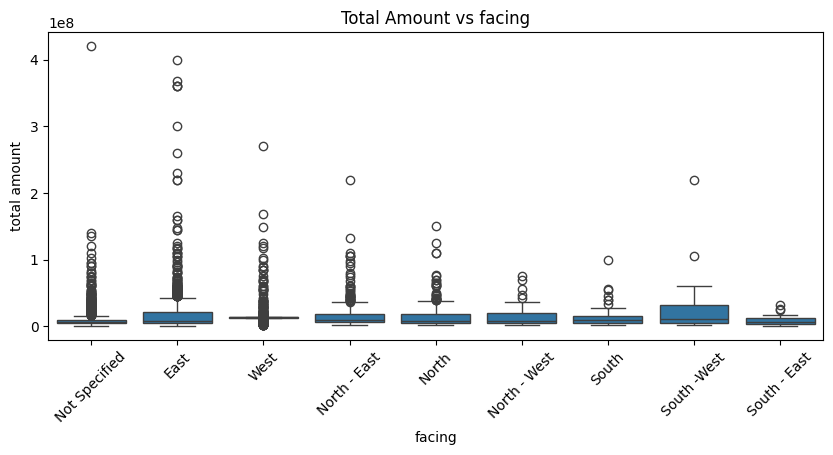

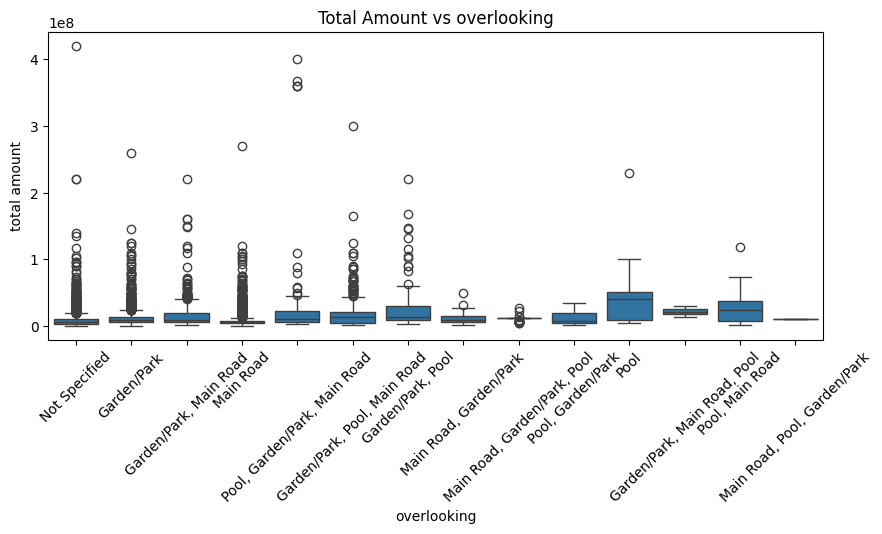

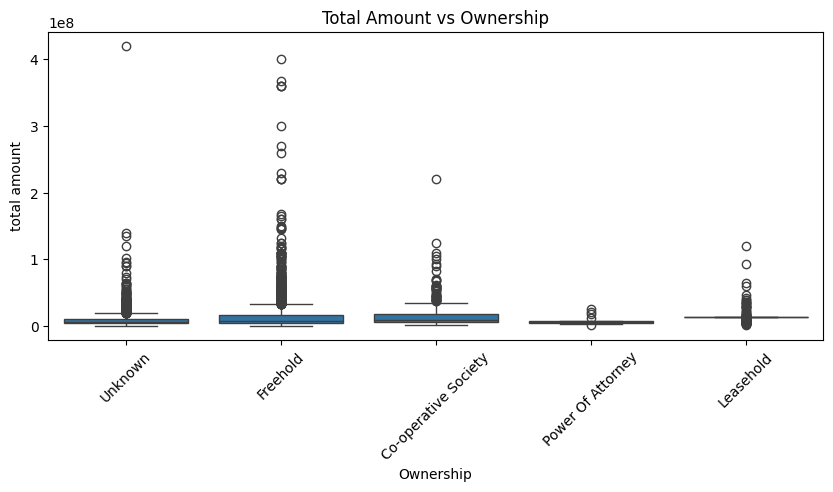

In [132]:
cat_cols = ['Status', 'Transaction', 'Furnishing', 'facing', 'overlooking', 'Ownership']

for col in cat_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=col, y='total amount', data=df)
    plt.xticks(rotation=45)
    plt.title(f'Total Amount vs {col}')
    plt.show()

### Columns to Consider Dropping

Given that 'Title' and 'Description' are textual and might not be directly useful for a numerical model without NLP, I recommend dropping them. Also, let's inspect the 'Society' column to check its cardinality.

In [133]:
# Drop 'Title' and 'Description' columns
df.drop(columns=['Title', 'Description'], inplace=True)

# Check the number of unique values in the 'Society' column
print(f"Number of unique values in 'Society': {df['Society'].nunique()}")
print("Top 10 most frequent societies:")
print(df['Society'].value_counts().head(10))

# Display updated info to confirm drops and current state
df.info()

Number of unique values in 'Society': 1978
Top 10 most frequent societies:
Society
Unknown                       6001
Nebula Tower                   883
Swati Parkside                 315
Cloud 9                        301
kamnath sepal residency        296
Ashraya 9                      296
Adani Shantigram Waterlily     296
Sambhavnath Upvan              296
Swastik Riviera                294
Raj Harsh Appartment           293
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   total amount  14365 non-null  Int64  
 1   price         14365 non-null  float64
 2   location      14365 non-null  object 
 3   Status        14365 non-null  object 
 4   Transaction   14365 non-null  object 
 5   Furnishing    14365 non-null  object 
 6   facing        14365 non-null  object 
 7   overlooking   14365 non-null  object 
 8

In [134]:
# Drop the 'Society' column due to high cardinality
df.drop(columns=['Society'], inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14365 entries, 0 to 14364
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   total amount  14365 non-null  Int64  
 1   price         14365 non-null  float64
 2   location      14365 non-null  object 
 3   Status        14365 non-null  object 
 4   Transaction   14365 non-null  object 
 5   Furnishing    14365 non-null  object 
 6   facing        14365 non-null  object 
 7   overlooking   14365 non-null  object 
 8   Bathroom      14365 non-null  Int64  
 9   Balcony       14365 non-null  Int64  
 10  Ownership     14365 non-null  object 
 11  Area          14365 non-null  float64
 12  Floor_Num     14365 non-null  float64
 13  Total_Floors  14365 non-null  float64
dtypes: Int64(3), float64(4), object(7)
memory usage: 1.6+ MB


In [136]:
X = df.drop('total amount',axis=1)
y = df['total amount']

In [137]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder

cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['number']).columns

X_ohe = pd.get_dummies(X, columns=cat_cols, drop_first=True)

X_le = X.copy()
le = LabelEncoder()
for col in cat_cols:
    X_le[col] = le.fit_transform(X_le[col].astype(str))

scaler = StandardScaler()

X_scaled_ohe = X_ohe.copy()
X_scaled_ohe = pd.DataFrame(scaler.fit_transform(X_scaled_ohe), columns=X_ohe.columns)

X_scaled_le = X_le.copy()
X_scaled_le = pd.DataFrame(scaler.fit_transform(X_scaled_le), columns=X_le.columns)

In [135]:

from sklearn.linear_model import LinearRegression


from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

In [143]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

datasets = {
    'One-Hot Encoded Data': X_ohe,
    'Label Encoded Data': X_le,
    'Scaled One-Hot Encoded Data': X_scaled_ohe,
    'Scaled Label Encoded Data': X_scaled_le
}

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(),
    'K-Nearest Neighbors Regressor': KNeighborsRegressor()
}

results = {}

for data_name, X_data in datasets.items():
    X_train, X_test, y_train, y_test = train_test_split(X_data, y, test_size=0.2, random_state=42)

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)

        key = f"Dataset: {data_name} | Model: {model_name}"
        results[key] = {
            'Accuracy (R2 Score)': r2,
            'Root Mean Squared Error (RMSE)': rmse,
            'Mean Absolute Error (MAE)': mae
        }

print("="*60)
print("REAL ESTATE PRICE PREDICTION MODEL EVALUATION REPORT")
print("="*60 + "\n")

for k, v in results.items():
    print(f"[{k}]")
    print(f" -> Accuracy Score (R2): {v['Accuracy (R2 Score)']:.4f} ({(v['Accuracy (R2 Score)'] * 100):.2f}% variance explained)")
    print(f" -> Root Mean Squared Error: {v['Root Mean Squared Error (RMSE)']:,.2f} rupees")
    print(f" -> Mean Absolute Error: {v['Mean Absolute Error (MAE)']:,.2f} rupees")
    print("-" * 60)


REAL ESTATE PRICE PREDICTION MODEL EVALUATION REPORT

[Dataset: One-Hot Encoded Data | Model: Linear Regression]
 -> Accuracy Score (R2): 0.7284 (72.84% variance explained)
 -> Root Mean Squared Error: 9,136,786.39 rupees
 -> Mean Absolute Error: 2,737,873.80 rupees
------------------------------------------------------------
[Dataset: One-Hot Encoded Data | Model: Decision Tree Regressor]
 -> Accuracy Score (R2): 0.8989 (89.89% variance explained)
 -> Root Mean Squared Error: 5,574,074.51 rupees
 -> Mean Absolute Error: 475,819.70 rupees
------------------------------------------------------------
[Dataset: One-Hot Encoded Data | Model: K-Nearest Neighbors Regressor]
 -> Accuracy Score (R2): 0.8676 (86.76% variance explained)
 -> Root Mean Squared Error: 6,379,441.22 rupees
 -> Mean Absolute Error: 615,955.45 rupees
------------------------------------------------------------
[Dataset: Label Encoded Data | Model: Linear Regression]
 -> Accuracy Score (R2): 0.7273 (72.73% variance expl